## 1. Reading in the data
We have to first read the data from the *data* directory. We will use -9999 for missing values and convert them to N/A. Additionally, we will use whitespace as the delimiter. 

In [1]:
# All imports needed in this notebook in one cell to simplify importing
import pandas as pd
from math import isnan
import matplotlib.pyplot as plt

In [2]:
# Define path for the data file
file = r'data/2315676.txt'
# Read the date using whitespace as the delimiter, -9999 as missing values, 0th row as the header and
# additionally skip 1st row where there is just dashes
data = pd.read_csv(file, delim_whitespace=True, na_values=[-9999], header=[0], skiprows=[1])
# Print data
print(data)
# Get the number of original data rows
orig_n = len(data)

                 STATION      STATION_NAME      DATE  TAVG  TMAX  TMIN
0      GHCND:FI000007501  SODANKYLA-AWS-FI  19080101   NaN   2.0 -37.0
1      GHCND:FI000007501  SODANKYLA-AWS-FI  19080102   NaN   6.0 -26.0
2      GHCND:FI000007501  SODANKYLA-AWS-FI  19080103   NaN   7.0 -27.0
3      GHCND:FI000007501  SODANKYLA-AWS-FI  19080104   NaN  -3.0 -27.0
4      GHCND:FI000007501  SODANKYLA-AWS-FI  19080105   NaN   4.0 -36.0
...                  ...               ...       ...   ...   ...   ...
41060  GHCND:FI000007501  SODANKYLA-AWS-FI  20201003  47.0  51.0   NaN
41061  GHCND:FI000007501  SODANKYLA-AWS-FI  20201004  43.0  47.0  37.0
41062  GHCND:FI000007501  SODANKYLA-AWS-FI  20201005  42.0   NaN  37.0
41063  GHCND:FI000007501  SODANKYLA-AWS-FI  20201006  45.0  46.0  43.0
41064  GHCND:FI000007501  SODANKYLA-AWS-FI  20201007  47.0  50.0  44.0

[41065 rows x 6 columns]


## 2. Calculating estimated temperatures
We can immediately see that there are some missing values in the TAVG column. For those columns, we can estimate an average by averaging the TMAX and TMIN values. However, there are some rows where either of those values is missing. For rows where either of the TMAX and TMIN values is missing, the return value for the calculation will also be N/A. 

In [3]:
# Calculate estimated average for all rows. 
data['ESTAVG'] = (data['TMAX'] + data['TMIN'])/2
# Take copy of the data for a future sanity check
data_copy = data.copy()
# Drop rows where both the TAVG and ESTAVG values are missing
data = data.dropna(axis=0, how='all', subset=['TAVG', 'ESTAVG'])
# Get the number of rows after dropping the N/A rows
fil_n = len(data)
print(data)

                 STATION      STATION_NAME      DATE  TAVG  TMAX  TMIN  ESTAVG
0      GHCND:FI000007501  SODANKYLA-AWS-FI  19080101   NaN   2.0 -37.0   -17.5
1      GHCND:FI000007501  SODANKYLA-AWS-FI  19080102   NaN   6.0 -26.0   -10.0
2      GHCND:FI000007501  SODANKYLA-AWS-FI  19080103   NaN   7.0 -27.0   -10.0
3      GHCND:FI000007501  SODANKYLA-AWS-FI  19080104   NaN  -3.0 -27.0   -15.0
4      GHCND:FI000007501  SODANKYLA-AWS-FI  19080105   NaN   4.0 -36.0   -16.0
...                  ...               ...       ...   ...   ...   ...     ...
41060  GHCND:FI000007501  SODANKYLA-AWS-FI  20201003  47.0  51.0   NaN     NaN
41061  GHCND:FI000007501  SODANKYLA-AWS-FI  20201004  43.0  47.0  37.0    42.0
41062  GHCND:FI000007501  SODANKYLA-AWS-FI  20201005  42.0   NaN  37.0     NaN
41063  GHCND:FI000007501  SODANKYLA-AWS-FI  20201006  45.0  46.0  43.0    44.5
41064  GHCND:FI000007501  SODANKYLA-AWS-FI  20201007  47.0  50.0  44.0    47.0

[40882 rows x 7 columns]


We can see that the number of rows we filtered out is

In [4]:
print(orig_n - fil_n)

183


We can confirm that the number of dropped rows make sense by selecting those rows from the *data* in a different way. We will select the rows where both of those are missing. Then as we use *len()* for the selection we should have 183 rows. Let's do it! 

In [5]:
# Select rows where both TAVG and ESTAVG are missing
len(data_copy.loc[(data_copy['TAVG'].isna()) & (data_copy['ESTAVG'].isna())])

183

which confirms, that the *dropna* worked as it should.

## 3. Temperature unit conversion
In the original data, all the temperatures are given in Fahrenheit so we have to convert them to Celsius using the function we'll define here next.

In [6]:
def fahr_to_celsius(temp_fahrenheit):
    """
    Converts temperature values given in Fahrenheit (param: temp_fahrenheit) to Celsius degrees.
    Usage: fahr_to_celsius(48)
    """
    converted_temp = (temp_fahrenheit - 32) / 1.8
    return converted_temp

Then we can use the function for the average temperature columns. Let's define new columns for them with the prefix *C_*:

In [7]:
# Convert AVG to Celsius
data['C_TAVG'] = data['TAVG'].apply(fahr_to_celsius)
# Convert ESTAVG to Celsius
data['C_ESTAVG'] = data['ESTAVG'].apply(fahr_to_celsius)
#print(data[''])

Then we have to combine the two Series for average temperature favoring the actual average over the estimated. Reading the documentation of Pandas it seems *Pandas.Series.combine_first()* does absolutely that. Let' use it!

In [8]:
# Create a Series for combined average temperatures
data['C_COMB_AVG'] = data['C_TAVG'].combine_first(data['C_ESTAVG'])

In [9]:
# Print out the average temperature columns
data[['C_TAVG', 'C_ESTAVG', 'C_COMB_AVG']]

,C_TAVG,C_ESTAVG,C_COMB_AVG
0,NaN,-27.500000,-27.500000
1,NaN,-23.333333,-23.333333
2,NaN,-23.333333,-23.333333
3,NaN,-26.111111,-26.111111
4,NaN,-26.666667,-26.666667
...,...,...,...
41060,8.333333,NaN,8.333333
41061,6.111111,5.555556,6.111111
41062,5.555556,NaN,5.555556
41063,7.222222,6.944444,7.222222


It now seems we got just what we wanted, as it seems like C_TAVG is favored over C_ESTAVG. Let's check if there are any NaN left. There shouldn't. 

In [10]:
# Count the number of NaN
data['C_COMB_AVG'].isna().sum()

0

As expected, there are no NaN values left so we can continue to the next step.

## 4. Calculating seasonal average temperatures
As we look into the task of calculating the seasonal average temperatures, we notice that the *winter* season begins in December and ends after February. Therefore, it's evident the winter season takes place during two years, although we have to confine it two one year to have the analysis make sense. We define new term *seasonal year*, label it $s\_year$, which defines in which yearly season the monthly temperature belongs. In this case, we define that December always belongs to the next years winter season rather than the current year. We could also use the months Jan, Feb and December but somehow the analysis seems more meaningful if there are no gaps between the months. For example, by this definition, 2021-12-1 would get assigned $s\_year = 2022$ and every other month would get the actual year as the seasonal year. In essence, the winter season of 1909 begins, by definition, in 1908.

In [11]:
# First, we need to get the actual year and month from the DATE column
data['YEAR'] = data['DATE'].astype(str).str.slice(start=0, stop=4).astype(int)
data['MONTH'] = data['DATE'].astype(str).str.slice(start=4, stop=6).astype(int)
# Print the date, year and month
print(data[['DATE', 'YEAR', 'MONTH']])
# Let's assign seasonal year and add it as a column to the data

           DATE  YEAR  MONTH
0      19080101  1908      1
1      19080102  1908      1
2      19080103  1908      1
3      19080104  1908      1
4      19080105  1908      1
...         ...   ...    ...
41060  20201003  2020     10
41061  20201004  2020     10
41062  20201005  2020     10
41063  20201006  2020     10
41064  20201007  2020     10

[40882 rows x 3 columns]


In [12]:
# Let's assign seasonal year and add it as a column to the dataframe. 
# Assign first according to the usual year but fix later for December
data['S_YEAR'] = data['YEAR']
# Now fix December
data.loc[data['MONTH'] == 12, 'S_YEAR'] = data['S_YEAR'] + 1

In [13]:
# Let's print the dates to see that the assignment looks OK
print(data[['DATE', 'YEAR', 'MONTH', 'S_YEAR']].loc[data['MONTH'] == 12])

           DATE  YEAR  MONTH  S_YEAR
335    19081201  1908     12    1909
336    19081202  1908     12    1909
337    19081203  1908     12    1909
338    19081204  1908     12    1909
339    19081205  1908     12    1909
...         ...   ...    ...     ...
40780  20191227  2019     12    2020
40781  20191228  2019     12    2020
40782  20191229  2019     12    2020
40783  20191230  2019     12    2020
40784  20191231  2019     12    2020

[3445 rows x 4 columns]


In [14]:
# Then also all the date data, not just for December
print(data[['DATE', 'YEAR', 'MONTH', 'S_YEAR']])

           DATE  YEAR  MONTH  S_YEAR
0      19080101  1908      1    1908
1      19080102  1908      1    1908
2      19080103  1908      1    1908
3      19080104  1908      1    1908
4      19080105  1908      1    1908
...         ...   ...    ...     ...
41060  20201003  2020     10    2020
41061  20201004  2020     10    2020
41062  20201005  2020     10    2020
41063  20201006  2020     10    2020
41064  20201007  2020     10    2020

[40882 rows x 4 columns]


Both seem to be following the definition we gave, so we can go forward with it. Let's assign the seasons next.

In [15]:
# Let's start by assigning something to the column SEASON
data['SEASON'] = ""
# Then we will select and assign each season separately
data.loc[data['MONTH'].isin([12,1,2]), 'SEASON'] = 'WINTER'
# Then select those months to check that the assignment worked correctly and print
print(data.loc[data['MONTH'].isin([1,2,12]), ['MONTH', 'SEASON']])
print(data.loc[data['MONTH'].isin([12]), ['MONTH', 'SEASON']])

       MONTH  SEASON
0          1  WINTER
1          1  WINTER
2          1  WINTER
3          1  WINTER
4          1  WINTER
...      ...     ...
40840      2  WINTER
40841      2  WINTER
40842      2  WINTER
40843      2  WINTER
40844      2  WINTER

[10093 rows x 2 columns]
       MONTH  SEASON
335       12  WINTER
336       12  WINTER
337       12  WINTER
338       12  WINTER
339       12  WINTER
...      ...     ...
40780     12  WINTER
40781     12  WINTER
40782     12  WINTER
40783     12  WINTER
40784     12  WINTER

[3445 rows x 2 columns]


In [16]:
# Then do the rest of the seasons
data.loc[data['MONTH'].isin([3,4,5]), 'SEASON'] = 'SPRING'
# Then select those months to check that the assignment worked correctly and print
print(data.loc[data['MONTH'].isin([3,4,5]), ['MONTH', 'SEASON']])
print(data.loc[data['MONTH'].isin([4]), ['MONTH', 'SEASON']])

       MONTH  SEASON
60         3  SPRING
61         3  SPRING
63         3  SPRING
64         3  SPRING
65         3  SPRING
...      ...     ...
40932      5  SPRING
40933      5  SPRING
40934      5  SPRING
40935      5  SPRING
40936      5  SPRING

[10308 rows x 2 columns]
       MONTH  SEASON
91         4  SPRING
92         4  SPRING
93         4  SPRING
94         4  SPRING
95         4  SPRING
...      ...     ...
40901      4  SPRING
40902      4  SPRING
40903      4  SPRING
40904      4  SPRING
40905      4  SPRING

[3338 rows x 2 columns]


In [17]:
data.loc[data['MONTH'].isin([6,7,8]), 'SEASON'] = 'SUMMER'
# Then select those months to check that the assignment worked correctly and print
print(data.loc[data['MONTH'].isin([6,7,8]), ['MONTH', 'SEASON']])
print(data.loc[data['MONTH'].isin([7]), ['MONTH', 'SEASON']])

       MONTH  SEASON
152        6  SUMMER
153        6  SUMMER
154        6  SUMMER
155        6  SUMMER
156        6  SUMMER
...      ...     ...
41023      8  SUMMER
41024      8  SUMMER
41025      8  SUMMER
41026      8  SUMMER
41027      8  SUMMER

[10385 rows x 2 columns]
       MONTH  SEASON
182        7  SUMMER
183        7  SUMMER
184        7  SUMMER
185        7  SUMMER
186        7  SUMMER
...      ...     ...
40993      7  SUMMER
40994      7  SUMMER
40995      7  SUMMER
40996      7  SUMMER
40997      7  SUMMER

[3495 rows x 2 columns]


In [18]:
data.loc[data['MONTH'].isin([9,10,11]), 'SEASON'] = 'AUTUMN'
# Then select those months to check that the assignment worked correctly and print
print(data.loc[data['MONTH'].isin([9,10,11]), ['MONTH', 'SEASON']])
print(data.loc[data['MONTH'].isin([10]), ['MONTH', 'SEASON']])

       MONTH  SEASON
244        9  AUTUMN
245        9  AUTUMN
246        9  AUTUMN
247        9  AUTUMN
248        9  AUTUMN
...      ...     ...
41060     10  AUTUMN
41061     10  AUTUMN
41062     10  AUTUMN
41063     10  AUTUMN
41064     10  AUTUMN

[10096 rows x 2 columns]
       MONTH  SEASON
274       10  AUTUMN
275       10  AUTUMN
276       10  AUTUMN
277       10  AUTUMN
278       10  AUTUMN
...      ...     ...
41060     10  AUTUMN
41061     10  AUTUMN
41062     10  AUTUMN
41063     10  AUTUMN
41064     10  AUTUMN

[3439 rows x 2 columns]


Let's print all the useful columns for change for all months just as a sanity check

In [19]:
data.loc[data['MONTH'].isin([1,2]), ['STATION', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG']]

,STATION,YEAR,MONTH,SEASON,S_YEAR,C_COMB_AVG
0,GHCND:FI000007501,1908,1,WINTER,1908,-27.500000
1,GHCND:FI000007501,1908,1,WINTER,1908,-23.333333
2,GHCND:FI000007501,1908,1,WINTER,1908,-23.333333
3,GHCND:FI000007501,1908,1,WINTER,1908,-26.111111
4,GHCND:FI000007501,1908,1,WINTER,1908,-26.666667
...,...,...,...,...,...,...
40840,GHCND:FI000007501,2020,2,WINTER,2020,-13.333333
40841,GHCND:FI000007501,2020,2,WINTER,2020,-18.888889
40842,GHCND:FI000007501,2020,2,WINTER,2020,-11.666667
40843,GHCND:FI000007501,2020,2,WINTER,2020,-10.555556


In [20]:
data.loc[data['MONTH'].isin([3,4]), ['STATION', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG']]

,STATION,YEAR,MONTH,SEASON,S_YEAR,C_COMB_AVG
60,GHCND:FI000007501,1908,3,SPRING,1908,-4.722222
61,GHCND:FI000007501,1908,3,SPRING,1908,-6.944444
63,GHCND:FI000007501,1908,3,SPRING,1908,-8.888889
64,GHCND:FI000007501,1908,3,SPRING,1908,-12.777778
65,GHCND:FI000007501,1908,3,SPRING,1908,-3.333333
...,...,...,...,...,...,...
40901,GHCND:FI000007501,2020,4,SPRING,2020,0.555556
40902,GHCND:FI000007501,2020,4,SPRING,2020,-1.111111
40903,GHCND:FI000007501,2020,4,SPRING,2020,-1.111111
40904,GHCND:FI000007501,2020,4,SPRING,2020,-1.666667


In [21]:
data.loc[data['MONTH'].isin([5,6]), ['STATION', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG']]

,STATION,YEAR,MONTH,SEASON,S_YEAR,C_COMB_AVG
122,GHCND:FI000007501,1908,5,SPRING,1908,0.000000
123,GHCND:FI000007501,1908,5,SPRING,1908,-2.222222
124,GHCND:FI000007501,1908,5,SPRING,1908,-2.777778
125,GHCND:FI000007501,1908,5,SPRING,1908,-2.500000
126,GHCND:FI000007501,1908,5,SPRING,1908,-2.777778
...,...,...,...,...,...,...
40962,GHCND:FI000007501,2020,6,SUMMER,2020,16.666667
40963,GHCND:FI000007501,2020,6,SUMMER,2020,11.666667
40964,GHCND:FI000007501,2020,6,SUMMER,2020,15.000000
40965,GHCND:FI000007501,2020,6,SUMMER,2020,17.222222


In [22]:
data.loc[data['MONTH'].isin([7,8]), ['STATION', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG']]

,STATION,YEAR,MONTH,SEASON,S_YEAR,C_COMB_AVG
182,GHCND:FI000007501,1908,7,SUMMER,1908,9.166667
183,GHCND:FI000007501,1908,7,SUMMER,1908,6.666667
184,GHCND:FI000007501,1908,7,SUMMER,1908,4.722222
185,GHCND:FI000007501,1908,7,SUMMER,1908,5.277778
186,GHCND:FI000007501,1908,7,SUMMER,1908,9.444444
...,...,...,...,...,...,...
41023,GHCND:FI000007501,2020,8,SUMMER,2020,7.222222
41024,GHCND:FI000007501,2020,8,SUMMER,2020,7.777778
41025,GHCND:FI000007501,2020,8,SUMMER,2020,10.000000
41026,GHCND:FI000007501,2020,8,SUMMER,2020,10.555556


In [23]:
data.loc[data['MONTH'].isin([9,10]), ['STATION', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG']]

,STATION,YEAR,MONTH,SEASON,S_YEAR,C_COMB_AVG
244,GHCND:FI000007501,1908,9,AUTUMN,1908,7.777778
245,GHCND:FI000007501,1908,9,AUTUMN,1908,10.555556
246,GHCND:FI000007501,1908,9,AUTUMN,1908,6.666667
247,GHCND:FI000007501,1908,9,AUTUMN,1908,9.444444
248,GHCND:FI000007501,1908,9,AUTUMN,1908,4.722222
...,...,...,...,...,...,...
41060,GHCND:FI000007501,2020,10,AUTUMN,2020,8.333333
41061,GHCND:FI000007501,2020,10,AUTUMN,2020,6.111111
41062,GHCND:FI000007501,2020,10,AUTUMN,2020,5.555556
41063,GHCND:FI000007501,2020,10,AUTUMN,2020,7.222222


In [24]:
data.loc[data['MONTH'].isin([11,12]), ['STATION', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG']]

,STATION,YEAR,MONTH,SEASON,S_YEAR,C_COMB_AVG
305,GHCND:FI000007501,1908,11,AUTUMN,1908,0.555556
306,GHCND:FI000007501,1908,11,AUTUMN,1908,-1.666667
307,GHCND:FI000007501,1908,11,AUTUMN,1908,-7.222222
308,GHCND:FI000007501,1908,11,AUTUMN,1908,-9.166667
309,GHCND:FI000007501,1908,11,AUTUMN,1908,-5.555556
...,...,...,...,...,...,...
40780,GHCND:FI000007501,2019,12,WINTER,2020,-19.444444
40781,GHCND:FI000007501,2019,12,WINTER,2020,-8.333333
40782,GHCND:FI000007501,2019,12,WINTER,2020,-0.555556
40783,GHCND:FI000007501,2019,12,WINTER,2020,-1.666667


In [25]:
# Let's create a column which combines the S_YEAR and SEASON and can be used for grouping
data['S_YEAR-SEASON'] = data['S_YEAR'].astype(str) + "-" + data['SEASON']
# Group by the column
grouped = data[['DATE', 'YEAR', 'MONTH', 'SEASON', 'S_YEAR', 'C_COMB_AVG', 'S_YEAR-SEASON']].groupby(['S_YEAR-SEASON'])

In [26]:
# Define the aggregated fields
mean_cols = ['C_COMB_AVG']
# Make a new dataframe for yearly seasonal data
ys_data = pd.DataFrame()

# Iterate over the groups
for key, group in grouped:
    # Calculate mean for the column
    mean_values = group[mean_cols].mean()

    # Add the ´key´ into the aggregated values
    mean_values['S_YEAR-SEASON'] = key

    # Append the aggregated values into the DataFrame
    ys_data = ys_data.append(mean_values, ignore_index=True)

In [27]:
ys_data

,C_COMB_AVG,S_YEAR-SEASON
0,-1.859217,1908-AUTUMN
1,-2.346743,1908-SPRING
2,11.425926,1908-SUMMER
3,-14.781746,1908-WINTER
4,-0.155827,1909-AUTUMN
...,...,...
447,-12.370370,2019-WINTER
448,7.717718,2020-AUTUMN
449,-0.827295,2020-SPRING
450,14.438339,2020-SUMMER


In [28]:
# Join the calculated yearly seasonal averages back to data
data = data.merge(ys_data, on="S_YEAR-SEASON")
# Print the data
data

,STATION,STATION_NAME,DATE,TAVG,TMAX,TMIN,ESTAVG,C_TAVG,C_ESTAVG,C_COMB_AVG_x,YEAR,MONTH,S_YEAR,SEASON,S_YEAR-SEASON,C_COMB_AVG_y
0,GHCND:FI000007501,SODANKYLA-AWS-FI,19080101,NaN,2.0,-37.0,-17.5,NaN,-27.500000,-27.500000,1908,1,1908,WINTER,1908-WINTER,-14.781746
1,GHCND:FI000007501,SODANKYLA-AWS-FI,19080102,NaN,6.0,-26.0,-10.0,NaN,-23.333333,-23.333333,1908,1,1908,WINTER,1908-WINTER,-14.781746
2,GHCND:FI000007501,SODANKYLA-AWS-FI,19080103,NaN,7.0,-27.0,-10.0,NaN,-23.333333,-23.333333,1908,1,1908,WINTER,1908-WINTER,-14.781746
3,GHCND:FI000007501,SODANKYLA-AWS-FI,19080104,NaN,-3.0,-27.0,-15.0,NaN,-26.111111,-26.111111,1908,1,1908,WINTER,1908-WINTER,-14.781746
4,GHCND:FI000007501,SODANKYLA-AWS-FI,19080105,NaN,4.0,-36.0,-16.0,NaN,-26.666667,-26.666667,1908,1,1908,WINTER,1908-WINTER,-14.781746
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40877,GHCND:FI000007501,SODANKYLA-AWS-FI,20201003,47.0,51.0,NaN,NaN,8.333333,NaN,8.333333,2020,10,2020,AUTUMN,2020-AUTUMN,7.717718
40878,GHCND:FI000007501,SODANKYLA-AWS-FI,20201004,43.0,47.0,37.0,42.0,6.111111,5.555556,6.111111,2020,10,2020,AUTUMN,2020-AUTUMN,7.717718
40879,GHCND:FI000007501,SODANKYLA-AWS-FI,20201005,42.0,NaN,37.0,NaN,5.555556,NaN,5.555556,2020,10,2020,AUTUMN,2020-AUTUMN,7.717718
40880,GHCND:FI000007501,SODANKYLA-AWS-FI,20201006,45.0,46.0,43.0,44.5,7.222222,6.944444,7.222222,2020,10,2020,AUTUMN,2020-AUTUMN,7.717718


Now we have the yearly seasonal value, but we have to clean the dataframe a bit. Some columns are really badly named and some are not needed at all. 

In [29]:
data = data.rename(columns={'C_COMB_AVG_y': 'YEARLY_SEASONAL_AVG_TEMP', 'C_COMB_AVG_x': 'C_COMB_AVG'})

In [30]:
# Let's select only columns DATE, S_YEAR, SEASON, S_YEAR-SEASON and YEARLY_SEASONAL_AVG_TEMP
data = data[['DATE', 'S_YEAR', 'SEASON', 'S_YEAR-SEASON', 'C_COMB_AVG', 'YEARLY_SEASONAL_AVG_TEMP']]

In [31]:
# Print the data
data

,DATE,S_YEAR,SEASON,S_YEAR-SEASON,C_COMB_AVG,YEARLY_SEASONAL_AVG_TEMP
0,19080101,1908,WINTER,1908-WINTER,-27.500000,-14.781746
1,19080102,1908,WINTER,1908-WINTER,-23.333333,-14.781746
2,19080103,1908,WINTER,1908-WINTER,-23.333333,-14.781746
3,19080104,1908,WINTER,1908-WINTER,-26.111111,-14.781746
4,19080105,1908,WINTER,1908-WINTER,-26.666667,-14.781746
...,...,...,...,...,...,...
40877,20201003,2020,AUTUMN,2020-AUTUMN,8.333333,7.717718
40878,20201004,2020,AUTUMN,2020-AUTUMN,6.111111,7.717718
40879,20201005,2020,AUTUMN,2020-AUTUMN,5.555556,7.717718
40880,20201006,2020,AUTUMN,2020-AUTUMN,7.222222,7.717718


## 5. Calculating the seasonal reference temperature
Next, we'll calculate the seasonal reference temperatures. 

In [32]:
# Select only the dates from beginning of winter 1951 to end of Autumn 1980.
ref_data = data.loc[(data['DATE'] >= 19511201) & (data['DATE'] < 19801201)]
# Print the data as a sanity check
ref_data

,DATE,S_YEAR,SEASON,S_YEAR-SEASON,C_COMB_AVG,YEARLY_SEASONAL_AVG_TEMP
15775,19511201,1952,WINTER,1952-WINTER,-21.388889,-9.072039
15776,19511202,1952,WINTER,1952-WINTER,-21.944444,-9.072039
15777,19511203,1952,WINTER,1952-WINTER,-22.222222,-9.072039
15778,19511204,1952,WINTER,1952-WINTER,-18.055556,-9.072039
15779,19511205,1952,WINTER,1952-WINTER,-6.111111,-9.072039
...,...,...,...,...,...,...
26361,19801126,1980,AUTUMN,1980-AUTUMN,-7.222222,-2.777778
26362,19801127,1980,AUTUMN,1980-AUTUMN,-12.777778,-2.777778
26363,19801128,1980,AUTUMN,1980-AUTUMN,-30.555556,-2.777778
26364,19801129,1980,AUTUMN,1980-AUTUMN,-27.777778,-2.777778


In [33]:
# Group by SEASON and aggregate with mean
ref_grouped = data[['DATE', 'SEASON', 'S_YEAR', 'C_COMB_AVG']].groupby(['SEASON'])

In [34]:
seasonal_means = ref_grouped.aggregate({'C_COMB_AVG': 'mean'})
seasonal_means = seasonal_means.rename(columns={'C_COMB_AVG': 'SEASONAL_REF_TEMP'})
seasonal_means

,SEASONAL_REF_TEMP
SEASON,
AUTUMN,-0.434000
SPRING,-1.993220
SUMMER,12.463088
WINTER,-12.877159


In [35]:
data = data.merge(seasonal_means, on="SEASON")

In [36]:
# Print the data
data

,DATE,S_YEAR,SEASON,S_YEAR-SEASON,C_COMB_AVG,YEARLY_SEASONAL_AVG_TEMP,SEASONAL_REF_TEMP
0,19080101,1908,WINTER,1908-WINTER,-27.500000,-14.781746,-12.877159
1,19080102,1908,WINTER,1908-WINTER,-23.333333,-14.781746,-12.877159
2,19080103,1908,WINTER,1908-WINTER,-23.333333,-14.781746,-12.877159
3,19080104,1908,WINTER,1908-WINTER,-26.111111,-14.781746,-12.877159
4,19080105,1908,WINTER,1908-WINTER,-26.666667,-14.781746,-12.877159
...,...,...,...,...,...,...,...
40877,20201003,2020,AUTUMN,2020-AUTUMN,8.333333,7.717718,-0.434000
40878,20201004,2020,AUTUMN,2020-AUTUMN,6.111111,7.717718,-0.434000
40879,20201005,2020,AUTUMN,2020-AUTUMN,5.555556,7.717718,-0.434000
40880,20201006,2020,AUTUMN,2020-AUTUMN,7.222222,7.717718,-0.434000


## 6. Calculating the anomalies
Let's calculate the anomalies by subtracting the reference temperature from the yearly seasonal average temperature

In [37]:
data['anomaly'] = data['YEARLY_SEASONAL_AVG_TEMP'] - data['SEASONAL_REF_TEMP']
data

,DATE,S_YEAR,SEASON,S_YEAR-SEASON,C_COMB_AVG,YEARLY_SEASONAL_AVG_TEMP,SEASONAL_REF_TEMP,anomaly
0,19080101,1908,WINTER,1908-WINTER,-27.500000,-14.781746,-12.877159,-1.904587
1,19080102,1908,WINTER,1908-WINTER,-23.333333,-14.781746,-12.877159,-1.904587
2,19080103,1908,WINTER,1908-WINTER,-23.333333,-14.781746,-12.877159,-1.904587
3,19080104,1908,WINTER,1908-WINTER,-26.111111,-14.781746,-12.877159,-1.904587
4,19080105,1908,WINTER,1908-WINTER,-26.666667,-14.781746,-12.877159,-1.904587
...,...,...,...,...,...,...,...,...
40877,20201003,2020,AUTUMN,2020-AUTUMN,8.333333,7.717718,-0.434000,8.151718
40878,20201004,2020,AUTUMN,2020-AUTUMN,6.111111,7.717718,-0.434000,8.151718
40879,20201005,2020,AUTUMN,2020-AUTUMN,5.555556,7.717718,-0.434000,8.151718
40880,20201006,2020,AUTUMN,2020-AUTUMN,7.222222,7.717718,-0.434000,8.151718


## 7. Plotting the data
Now we can finally plot the data. Let's start by selecting the data corresponding to each season. However, we only need the 'anomaly' and DATE columns

In [38]:
data['DATE_STR'] = data['DATE'].astype(str)
data['DATETIME'] = pd.to_datetime(data['DATE_STR'], format='%Y%m%d')
data.set_index('DATETIME', inplace=True)

In [39]:
winter_data = data[['anomaly']].loc[data['SEASON'] == 'WINTER']
winter_data

,anomaly
DATETIME,
1908-01-01,-1.904587
1908-01-02,-1.904587
1908-01-03,-1.904587
1908-01-04,-1.904587
1908-01-05,-1.904587
...,...
2020-02-25,4.904021
2020-02-26,4.904021
2020-02-27,4.904021


In [40]:
spring_data = data[['anomaly']].loc[data['SEASON'] == 'SPRING']
spring_data

,anomaly
DATETIME,
1908-03-01,-0.353523
1908-03-02,-0.353523
1908-03-04,-0.353523
1908-03-05,-0.353523
1908-03-06,-0.353523
...,...
2020-05-27,1.165925
2020-05-28,1.165925
2020-05-29,1.165925


In [41]:
summer_data = data[['anomaly']].loc[data['SEASON'] == 'SUMMER']
summer_data

,anomaly
DATETIME,
1908-06-01,-1.037162
1908-06-02,-1.037162
1908-06-03,-1.037162
1908-06-04,-1.037162
1908-06-05,-1.037162
...,...
2020-08-27,1.975252
2020-08-28,1.975252
2020-08-29,1.975252


In [42]:
autumn_data = data[['anomaly']].loc[data['SEASON'] == 'AUTUMN']
autumn_data

,anomaly
DATETIME,
1908-09-01,-1.425217
1908-09-02,-1.425217
1908-09-03,-1.425217
1908-09-04,-1.425217
1908-09-05,-1.425217
...,...
2020-10-03,8.151718
2020-10-04,8.151718
2020-10-05,8.151718


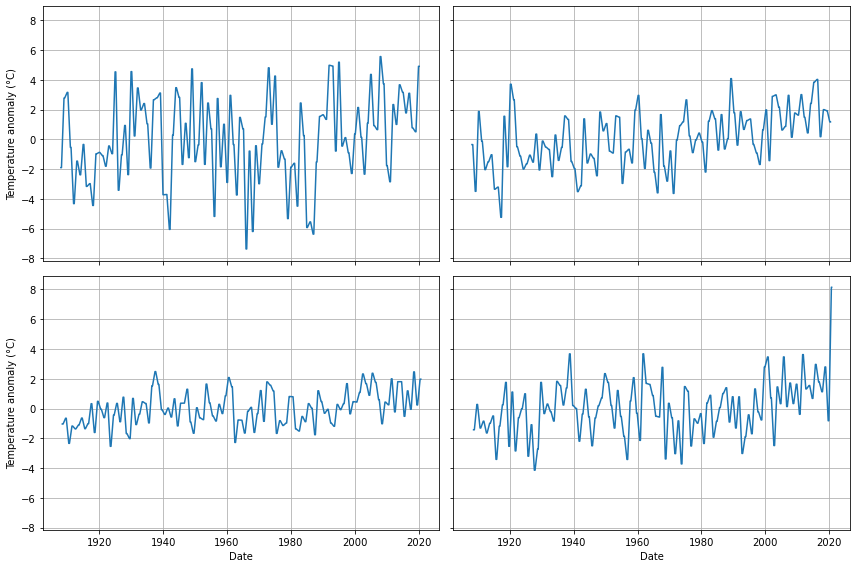

In [63]:
fig, axes = plt.subplots(nrows=2, ncols=2, sharex=True, sharey=True, figsize=(12,8))
plt.rcParams['axes.grid'] = True
data_list = ((winter_data, spring_data), (summer_data, autumn_data))
for j in range(0,1):
    for i in range(0,1):
        axes[j,i].plot(data_list[j,i].index, data_list[j,i])
axes[0,0].plot(winter_data.index, winter_data['anomaly'])
axes[0,1].plot(spring_data.index, spring_data['anomaly'])
axes[1,0].plot(summer_data.index, summer_data['anomaly'])
axes[1,1].plot(autumn_data.index, autumn_data['anomaly'])
axes[1,0].set_xlabel('Date')
axes[1,1].set_xlabel('Date')
axes[0,0].set_ylabel('Temperature anomaly (°C)')
axes[1,0].set_ylabel('Temperature anomaly (°C)')
plt.tight_layout()